# Set 13: EDA + AdaBoost (4 models)

**Q1 → Exp 1B / 2** · **Q2 → Exp 10** (AdaBoost)

Datasets: Q1 `Diabetes.csv`, Q2 `IRIS.csv` (3 species, so precision / recall use `average="macro"`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Q1.2 % of missing values per column, and drop the column if > 20%
The impossible zeros are the real missing values here, so turn them into NaN first.

In [3]:
zero_is_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)
pct = df.isnull().mean() * 100
print(pct.round(1))
drop_cols = pct[pct > 20].index
print("\nDropping (> 20% missing):", list(drop_cols))
df = df.drop(columns=drop_cols)

Pregnancies                  0.0
Glucose                      0.7
BloodPressure                4.6
SkinThickness               29.6
Insulin                     48.7
BMI                          1.4
DiabetesPedigreeFunction     0.0
Age                          0.0
Outcome                      0.0
dtype: float64

Dropping (> 20% missing): ['SkinThickness', 'Insulin']


### Q1.3 Scatter plot of two continuous variables

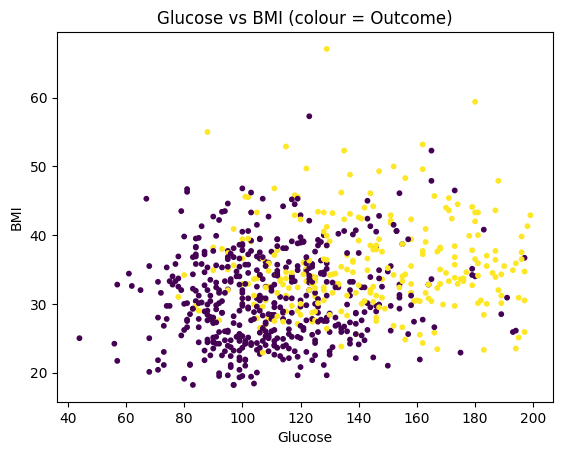

In [4]:
plt.scatter(df["Glucose"], df["BMI"], c=df["Outcome"], s=10)
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.title("Glucose vs BMI (colour = Outcome)")
plt.show()

### Q1.4 Label encoding of a categorical feature
Diabetes has no text column, so we make one (age groups) and encode it.

In [5]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[20, 30, 40, 50, 90], labels=["20s", "30s", "40s", "50+"])
from sklearn.preprocessing import LabelEncoder

print("Before:", df["AgeGroup"].unique()[:6])
df["AgeGroup"] = LabelEncoder().fit_transform(df["AgeGroup"].astype(str))
print("After :", df["AgeGroup"].unique()[:6])

Before: ['40s', '30s', '20s', '50+']
Categories (4, object): ['20s' < '30s' < '40s' < '50+']
After : [2 1 0 3]


### Q1.5 LDA for feature extraction
With 2 classes, LDA can make at most **1** new feature (classes − 1).

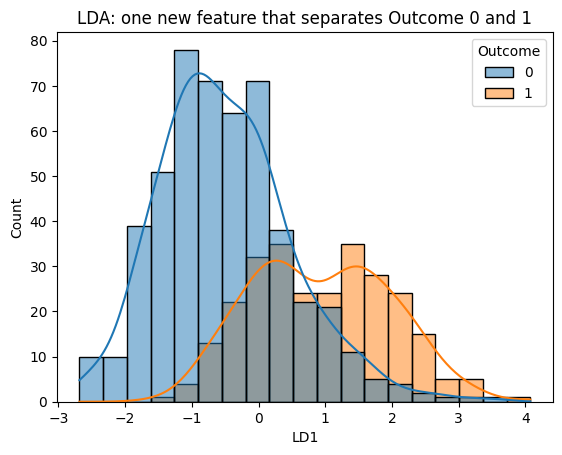

In [6]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X = df.drop(columns=["Outcome", "AgeGroup"]).fillna(df.median(numeric_only=True))
ld = LinearDiscriminantAnalysis(n_components=1).fit_transform(X, df["Outcome"])
sns.histplot(x=ld[:, 0], hue=df["Outcome"], kde=True)
plt.xlabel("LD1")
plt.title("LDA: one new feature that separates Outcome 0 and 1")
plt.show()

---
## Question 2

### Q2.1 Read the dataset and preprocess
### Q2.2 Choose X (independent) and Y (dependent)

*One code cell below answers both parts.*

In [7]:
df = pd.read_csv("data/IRIS.csv")
X = df.drop(columns="Species")
y = df["Species"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (112, 4)  Test: (38, 4)


### Q2.3 Four AdaBoost models with different parameters
### Q2.5 Confusion table, accuracy, precision, recall and F-score for each

*One code cell below answers both parts.*

In [8]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

params = [dict(n_estimators=10, learning_rate=1.0), dict(n_estimators=50, learning_rate=0.5),
          dict(n_estimators=100, learning_rate=0.1), dict(n_estimators=200, learning_rate=0.05)]
rows = []
for p in params:
    pred = AdaBoostClassifier(random_state=42, **p).fit(X_train, y_train).predict(X_test)
    print(p, "\n", confusion_matrix(y_test, pred))
    rows.append([str(p), accuracy_score(y_test, pred), precision_score(y_test, pred, average="macro"),
                 recall_score(y_test, pred, average="macro"), f1_score(y_test, pred, average="macro")])
pd.DataFrame(rows, columns=["Parameters", "Accuracy", "Precision", "Recall", "F-score"]).round(4)

{'n_estimators': 10, 'learning_rate': 1.0} 
 [[12  0  0]
 [ 0 12  1]
 [ 0  2 11]]


{'n_estimators': 50, 'learning_rate': 0.5} 
 [[12  0  0]
 [ 0 12  1]
 [ 0  3 10]]
{'n_estimators': 100, 'learning_rate': 0.1} 
 [[12  0  0]
 [ 0 12  1]
 [ 0  1 12]]


{'n_estimators': 200, 'learning_rate': 0.05} 
 [[12  0  0]
 [ 0 12  1]
 [ 0  1 12]]


,Parameters,Accuracy,Precision,Recall,F-score
0,"{'n_estimators': 10, 'learning_rate': 1.0}",0.9211,0.9246,0.9231,0.9230
1,"{'n_estimators': 50, 'learning_rate': 0.5}",0.8947,0.9030,0.8974,0.8968
2,"{'n_estimators': 100, 'learning_rate': 0.1}",0.9474,0.9487,0.9487,0.9487
3,"{'n_estimators': 200, 'learning_rate': 0.05}",0.9474,0.9487,0.9487,0.9487


### Q2.4 Find the best parameters and calculate Y_predict

In [9]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(AdaBoostClassifier(random_state=42),
                      {"n_estimators": [10, 50, 100, 200], "learning_rate": [0.05, 0.1, 0.5, 1.0]}, cv=5, n_jobs=-1).fit(X_train, y_train)
print("Best parameters:", search.best_params_)
y_pred = search.predict(X_test)
print("Y_predict:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Best parameters: {'learning_rate': 0.5, 'n_estimators': 10}
Y_predict: ['Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-virginica' 'Iris-virginica'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-virginica'
 'Iris-versicolor']
Accuracy: 0.9211
